# Теория к лабораторной работе 3. Доверительные интервалы

В лабораторных работах 1 и 2 мы строили *точечные оценки*: одно число $\hat\theta_n$, которое принимается за приближение неизвестного параметра $\theta$. 

Но одно число ничего не говорит о точности: по 10 наблюдениям и по 10 000 наблюдений мы получим по одному числу, а доверять им нужно по-разному.

*Доверительный интервал* отвечает на вопрос: «насколько можно доверять оценке». 

Вместо одного числа он дает диапазон вида «оценка $\pm$ погрешность» — так же, как результаты измерений записывают в физике или в A/B-тестах.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

## 1. Определение

Пусть $T_1(\mathbf{X})$, $T_2(\mathbf{X})$ - две статистики.

**Определение.** *Доверительным интервалом уровня доверия $1-\alpha$* для параметра $\theta$ называется интервал $[T_1(\mathbf{X}),\,T_2(\mathbf{X})]$, который накрывает $\theta$ с вероятностью $1-\alpha$:
$$\mathbb{P}\left[T_1(\mathbf{X})\le\theta\le T_2(\mathbf{X})\right]=1-\alpha$$
Если равенство выполняется лишь приближенно при больших $n$, интервал называют *асимптотическим*. Типичные уровни доверия: $0.9$, $0.95$, $0.99$.

**Как понимать уровень доверия.** 

*Границы* интервала $T_1$, $T_2$ — случайные величины, а $\theta$ — неизвестная константа. 

Например, при уровени доверия $1-\alpha=0.95$: если повторять эксперимент много раз, примерно 95% построенных интервалов накроют $\theta$. 

**Ошибочное понимание уровеня доверия.** 

$\theta$ — число, поэтому нельзя сказать, что «$\theta$ лежит в интервале $\left[T_1(\mathbf{X})\le\theta\le T_2(\mathbf{X})\right]$ с вероятностью 95%»

## 2. Построение доверительного интервала в случае, когда оценка имеет нормальное распределение

Пусть оценка $\hat\theta$ имеет нормальное распределение $\mathcal{N}\left(\theta,\sigma^2\right)$. Тогда:

1. стандартизуем: $Z=\dfrac{\hat\theta-\theta}{\sigma}\sim\mathcal{N}(0,1)$;
2. берем квантиль так, чтобы в «хвостах» осталось по $\alpha/2$: 
   $$\mathbb{P}\left(-z_{1-\alpha/2}\le Z\le z_{1-\alpha/2}\right)=1-\alpha$$
3. выражаем $\theta$ из неравенств и получаем интервал
$$\hat\theta-\sigma\cdot z_{1-\alpha/2}\le\theta\le\hat\theta+\sigma\cdot z_{1-\alpha/2}$$

Наиболее часто используемые квантили: 

- $z_{0.95}\approx1.645$ (уровень доверия 90%)
- $z_{0.975}\approx1.96$ (95%) 
- $z_{0.995}\approx2.576$ (99%). 

В `scipy` квантиль вычисляется функцией `stats.norm.ppf(q)` (ppf — percent point function, функция, обратная к функции распределения).

In [6]:
for level in [0.90, 0.95, 0.99]:
    print(f"уровень {level:.2f}: z = {stats.norm.ppf(1 - (1 - level) / 2):.3f}")

уровень 0.90: z = 1.645
уровень 0.95: z = 1.960
уровень 0.99: z = 2.576


z = 1.959963984540054


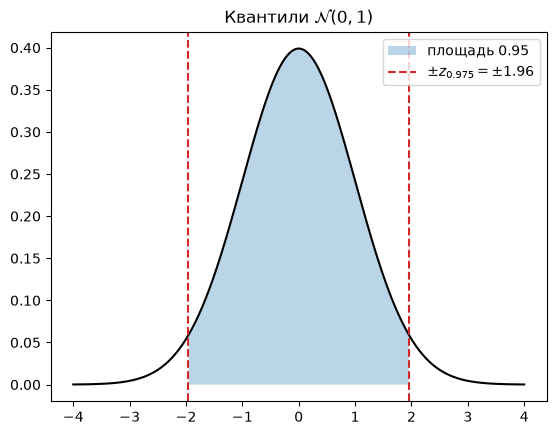

In [7]:
# уровень доверия 95%
alpha = 0.05

# квантиль
z = stats.norm.ppf(1 - alpha / 2)
print(f"z = {z}")

# построим стандартное нормальное распределение
grid = np.linspace(-4, 4, 400)
plt.plot(grid, stats.norm.pdf(grid), color="black")

# заполним фоном область в интервале [-z, z]
# пллощадь этой области равна уровню доверия = 0.95
inside = np.abs(grid) <= z
plt.fill_between(grid[inside], stats.norm.pdf(grid[inside]), alpha=0.3, label=f"площадь {1 - alpha:.2f}")

# квантили -z и +z отметим вертикальными красными линиями
plt.axvline(-z, color="C3", linestyle="--")
plt.axvline(z, color="C3", linestyle="--", label=rf"$\pm z_{{0.975}}=\pm{z:.2f}$")

plt.legend()
plt.title(r"Квантили $\mathcal{N}(0,1)$")
plt.show()

## 3. Построение доверительного интервала для выборки из нормального распределения

Пусть выборка имеет нормальное распределение 
$$X_i\sim\mathcal{N}\left(\mu,\sigma^2\right)$$
Хотим построить доверительный интервал для $\mu$ и $\sigma$ не известна.

В этом случае рассматривают статистику: 
$$T=\frac{\bar X_n-\mu}{S_n/\sqrt{n}}$$
где 
$$
    S_n^2=\frac{1}{n-1}\sum_{i=1}^n(X_i-\bar X_n)^2\,,\qquad
    \bar X_n=\frac1n\sum_{i=1}^n X_i
$$
Для выборки из нормального распределения статистика $T$ имеет *распределение Стьюдента* $t_{n-1}$ с $n-1$ степенями свободы. 

Оно похоже на $\mathcal{N}(0,1)$, но у него тяжелее хвост. При росте $n$ распределение $t_{n-1}$ приближается к $\mathcal{N}(0,1)$.

Поэтому при неизвестной $\sigma$ интервал для $\mu$ строится по тому же рецепту, но с квантилем распределения Стьюдента `stats.t.ppf(q, df=n - 1)` вместо $z$:
$$\bar X_n-t_{n-1,\,1-\alpha/2}\,\frac{S_n}{\sqrt n}\le\mu\le\bar X_n+t_{n-1,\,1-\alpha/2}\,\frac{S_n}{\sqrt n}$$
где $t_{n-1,\,q}$ — квантиль уровня $q$ распределения Стьюдента $t_{n-1}$. 

При малых $n$ разница существенна, при $n\gtrsim30$ — почти незаметна. 

**Асимптотический доверительный интервал.** При больших $n$ квантиль $t_{n-1,\,1-\alpha/2}$ можно заменить на $z_{1-\alpha/2}$:
$$\bar X_n-z_{1-\alpha/2}\,\frac{S_n}{\sqrt n}\le\mu\le\bar X_n+z_{1-\alpha/2}\,\frac{S_n}{\sqrt n}$$
Его уровень доверия равен $1-\alpha$ лишь приближенно, при $n\to\infty$. Зато, как будет показано в разделе 4, он годится и для ненормальных данных.

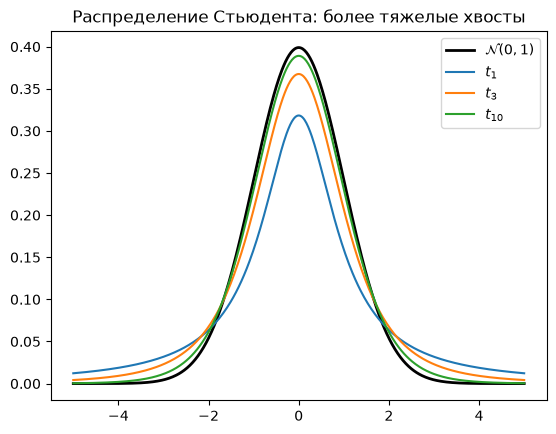

квантили уровня 0.975:
  N(0,1): 1.960
  t_2: 4.303
  t_5: 2.571
  t_10: 2.228
  t_30: 2.042
  t_100: 1.984


In [8]:
# построим стандартное нормальное распределение
grid = np.linspace(-5, 5, 500)
plt.plot(grid, stats.norm.pdf(grid), "k", lw=2, label=r"$\mathcal{N}(0,1)$")

# построим распределение Стьюдента для разных степенях свободы
for k in [1, 3, 10]:
    plt.plot(grid, stats.t.pdf(grid, df=k), label=f"$t_{{{k}}}$")

plt.legend()
plt.title("Распределение Стьюдента: более тяжелые хвосты")
plt.show()

# квантиль стандартного нормального распределения
print("квантили уровня 0.975:")
print(f"  N(0,1): {stats.norm.ppf(0.975):.3f}")

# та же квантиль для нескольких распределений Стьюдента
for k in [2, 5, 10, 30, 100]:
    print(f"  t_{k}: {stats.t.ppf(0.975, df=k):.3f}")

## 4. Большие выборки: центральная предельная теорема

Что делать, если данные не нормальные (время ответа сервера, число ошибок в логах, клик / не клик)? 

Помогает центральная предельная теорема.

**Центральная предельная теорема (ЦПТ).** Если $X_1,\dots,X_n$ независимы, одинаково распределены, $\mathbb{E}X_i=m$ и $\mathbb{D}X_i=s^2<\infty$, то при больших $n$ выборочное среднее имеет нормальное распределение:
$$\bar X_n\approx\mathcal{N}\left(m,\ \frac{s^2}{n}\right).$$

Значит, рецепт из раздела 2 работает для среднего почти любых данных, если $n$ велико. 

Неизвестную дисперсию в стандартной ошибке заменяют ее несмещенной оценкой по выборке — так получаются *асимптотические* доверительные интервалы. Для среднего $m$ асимптотический доверительный интервал уровня $1-\alpha$:
$$\bar X_n-z_{1-\alpha/2}\,\frac{S_n}{\sqrt n}\le m\le\bar X_n+z_{1-\alpha/2}\,\frac{S_n}{\sqrt n}$$
Он накрывает $m$ с вероятностью, близкой к $1-\alpha$ при больших $n$, и не требует, чтобы данные были нормальными. 

В общем виде асимптотический интервал записывают как «оценка $\pm$ квантиль $\times$ оценка стандартной ошибки»:
$$\hat\theta\pm z_{1-\alpha/2}\,\widehat{\mathrm{SE}}$$
Например, для вероятности успеха $p$ (данные из нулей и единиц) $\hat\theta=\hat p=\bar X_n$ и $\widehat{\mathrm{SE}}=\sqrt{\hat p(1-\hat p)/n}$ (см. пример 2).

**Экспоненциальное распределение** $\mathrm{Exp}(\lambda)$ с параметром $\lambda>0$ — типичная модель времени ожидания (время между запросами к серверу, время ответа). Его плотность и функция распределения:
$$
    f(x)=\lambda e^{-\lambda x},\qquad
    F(x)=\mathbb{P}(X\le x)=1-e^{-\lambda x},\qquad x\ge0.
$$
Математическое ожидание и дисперсия:
$$
    \mathbb{E}X=\frac1\lambda,\qquad
    \mathbb{D}X=\frac1{\lambda^2}.
$$

В Python распределение задается не через $\lambda$, а через *масштаб* `scale` $=1/\lambda$ (он же равен среднему):

- генерация выборки: `rng.exponential(scale=1/lam, size=n)`

- плотность: `stats.expon.pdf(x, scale=1/lam)` 

- функция распределения: `stats.expon.cdf(x, scale=1/lam)`

- квантиль: `stats.expon.ppf(q, scale=1/lam)`

- среднее и дисперсия: `stats.expon.mean(scale=1/lam)`, `stats.expon.var(scale=1/lam)`

выборочное среднее: 0.496, теоретическое 1/lambda: 0.500
выборочная дисперсия: 0.243, теоретическая 1/lambda^2: 0.250


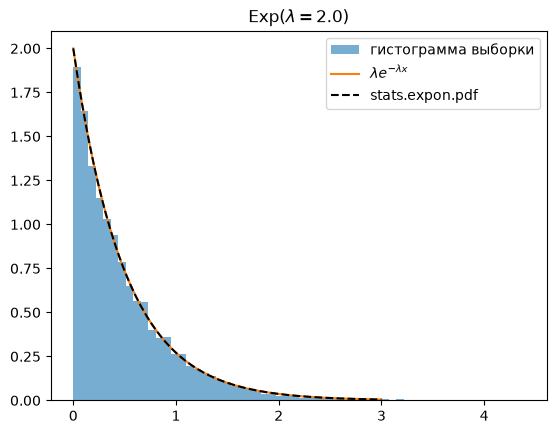

In [ ]:
lam = 2.0                  # параметр lambda
scale = 1 / lam            # в numpy и scipy передается scale = 1/lambda

# выборка из Exp(lambda)
x = rng.exponential(scale=scale, size=10000)

print(f"выборочное среднее: {x.mean():.3f}, теоретическое 1/lambda: {stats.expon.mean(scale=scale):.3f}")
print(f"выборочная дисперсия: {x.var(ddof=1):.3f}, теоретическая 1/lambda^2: {stats.expon.var(scale=scale):.3f}")

# гистограмма выборки
grid = np.linspace(0, 3, 300)
plt.hist(x, bins=60, density=True, alpha=0.6, label="гистограмма выборки")

# плотность по формуле и через scipy
plt.plot(grid, lam * np.exp(-lam * grid), label=r"$\lambda e^{-\lambda x}$")
plt.plot(grid, stats.expon.pdf(grid, scale=scale), "k--", label="stats.expon.pdf")

plt.title(rf"$\mathrm{{Exp}}(\lambda={lam})$")
plt.legend()
plt.show()

**Посмотрим на ЦПТ в действии**: исходное распределение — экспоненциальное (сильно несимметричное), а распределение среднего с ростом $n$ становится похожим на нормальное.

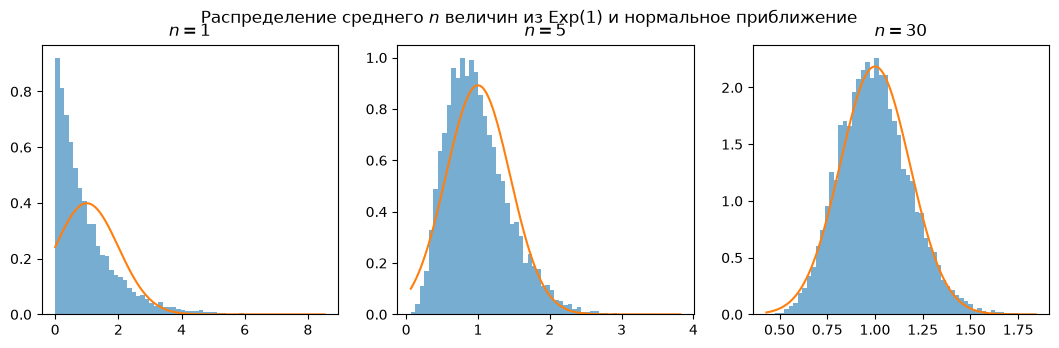

In [12]:
# сколько раз генерируем выборки
M = 10000

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

# k - объем выборки
for ax, k in zip(axes, [1, 5, 30]):
    # выборки из экспоненциального распределения
    X = rng.exponential(scale=1.0, size=(M, k))
    
    # выборочные средние
    hat_X = X.mean(axis=1)
    
    # гистограмма выборочных средних
    ax.hist(hat_X, bins=60, density=True, alpha=0.6)
        
    # график нормального распределения
    grid = np.linspace(hat_X.min(), hat_X.max(), 300)
    ax.plot(grid, stats.norm.pdf(grid, loc=1.0, scale=1.0 / np.sqrt(k)))
    
    ax.set_title(f"$n={k}$")

fig.suptitle(r"Распределение среднего $n$ величин из $\mathrm{Exp}(1)$ и нормальное приближение")
plt.show()

## 5. Примеры

**Пример 1 (время ответа сервиса)** 

Измерено время ответа сервиса на $n=16$ запросов: среднее $\bar x=210$ мс, выборочное стандартное отклонение $s=40$ мс. Считая данные нормальными, постройте 95%-й доверительный интервал для среднего времени ответа $\mu$.

alpha = 0.05, уровень квантиля q = 1 - alpha/2 = 0.975
степени свободы: n - 1 = 15
t_{15, 0.975} = 2.131
стандартная ошибка: s / sqrt(n) = 40 / 4 = 10.0 мс
полуширина: t * se = 2.131 * 10.0 = 21.3 мс
95%-й доверительный интервал: [188.7; 231.3] мс


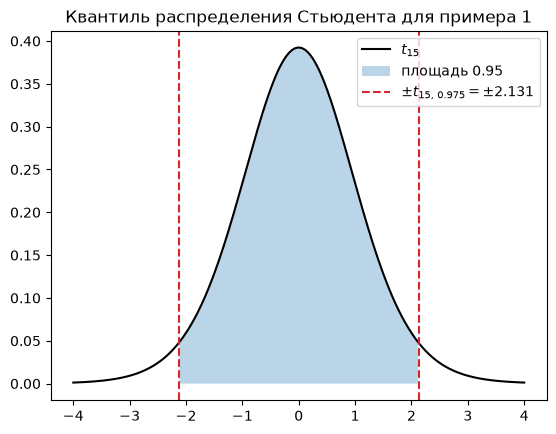

In [15]:
# Пример 1 (время ответа сервиса)

# Идея решения. Дисперсия sigma^2 неизвестна, поэтому вместо квантиля z
# нормального распределения берем квантиль распределения Стьюдента
# с n - 1 степенями свободы (раздел 4). Интервал имеет вид
#     x̄ ± t_{n-1, 1-alpha/2} * s / sqrt(n)

# исходные данные
n = 16          # число запросов (объем выборки)
x_bar = 210.0   # выборочное среднее, мс
s = 40.0        # выборочное стандартное отклонение, мс
level = 0.95    # уровень доверия 1 - alpha

# шаг 1: alpha и уровень квантиля
# в каждом хвосте распределения остается alpha/2, поэтому нужен квантиль уровня 1 - alpha/2
alpha = 1 - level
q = 1 - alpha / 2
print(f"alpha = {alpha:.2f}, уровень квантиля q = 1 - alpha/2 = {q:.3f}")

# шаг 2: число степеней свободы
# статистика T = (X̄ - mu) / (S / sqrt(n)) имеет распределение Стьюдента с n - 1 степенями свободы
df = n - 1
print(f"степени свободы: n - 1 = {df}")

# шаг 3: квантиль распределения Стьюдента t_{n - 1, 1 - alpha / 2}
# ppf — функция, обратная к функции распределения: P(T <= t) = q
t = stats.t.ppf(q, df=df)
print(f"t_{{{df}, {q}}} = {t:.3f}")

# шаг 4: стандартная ошибка среднего s / sqrt(n)
se = s / np.sqrt(n)
print(f"стандартная ошибка: s / sqrt(n) = {s:.0f} / {np.sqrt(n):.0f} = {se:.1f} мс")

# шаг 5: полуширина интервала = квантиль * стандартная ошибка
half = t * se
print(f"полуширина: t * se = {t:.3f} * {se:.1f} = {half:.1f} мс")

# шаг 6: интервал = оценка ± полуширина
low, high = x_bar - half, x_bar + half
print(f"95%-й доверительный интервал: [{low:.1f}; {high:.1f}] мс")

# квантиль и плотность t_15 на графике: площадь между -t и t равна 0.95
grid = np.linspace(-4, 4, 400)
plt.plot(grid, stats.t.pdf(grid, df=df), color="black", label=f"$t_{{{df}}}$")
inside = np.abs(grid) <= t
plt.fill_between(grid[inside], stats.t.pdf(grid[inside], df=df), alpha=0.3, label=f"площадь {level:.2f}")
plt.axvline(-t, color="C3", linestyle="--")
plt.axvline(t, color="C3", linestyle="--", label=rf"$\pm t_{{{df},\,{q}}}=\pm{t:.3f}$")
plt.legend()
plt.title("Квантиль распределения Стьюдента для примера 1")
plt.show()

**Пример 2 (конверсия).** *Конверсией* в веб-аналитике называют долю посетителей, совершивших целевое действие (покупку, регистрацию, клик по кнопке). 

Из $n=1000$ посетителей сайта $37$ совершили покупку. Постройте 95%-й доверительный интервал для вероятности покупки $p$.

**Решение.** 

Пусть $X_i=1$, если $i$-й посетитель совершил покупку, и $X_i=0$ иначе (распределение Бернулли). 

Тогда $\mathbb{E}X_i=p$, $\mathbb{D}X_i=p(1-p)$, оценка $\hat p=\bar x=37/1000=0.037$. 

По ЦПТ $\hat p\approx\mathcal{N}(p,\,p(1-p)/n)$. 

Неизвестное $p$ в стандартной ошибке заменяем на $\hat p$:
$$\sigma=\sqrt{\frac{\hat p(1-\hat p)}{n}}=\sqrt{\frac{0.037\cdot0.963}{1000}}\approx0.0060.$$
Так как $\hat p$ приближенно нормальна, квантиль берем у стандартного нормального распределения $\mathcal{N}(0,1)$. Уровень доверия $1-\alpha=0.95$, значит $\alpha=0.05$ и в каждом хвосте остается $\alpha/2=0.025$. Нужен квантиль уровня $1-\alpha/2=0.975$, то есть число $z_{0.975}$, для которого
$$\mathbb{P}(Z\le z_{0.975})=\int_{-\infty}^{z_{0.975}}\frac{1}{\sqrt{2\pi}}e^{-x^2/2}\,dx=0.975,\qquad Z\sim\mathcal{N}(0,1).$$
Этот интеграл через элементарные функции не берется, поэтому квантиль находят численно: `stats.norm.ppf(0.975)` $=1.95996\ldots\approx1.96$ (или по таблице квантилей нормального распределения).

Интервал: $0.037\pm1.96\cdot0.0060=0.037\pm0.0117$, то есть $[0.025;\ 0.049]$, или $3.7\%\pm1.2\%$.

## 6. Практическая часть: что и как считать

### 6.1. Готовые функции `scipy`

Доверительные интервалы можно получить готовыми функциями: 

- `stats.norm.interval(confidence, loc, scale)` 

- `stats.t.interval(confidence, df, loc, scale)`. 

В них `loc` — оценка, `scale` — стандартная ошибка. 

Стандартную ошибку среднего $s_n/\sqrt{n}$ вычисляет функция 

- `stats.sem(x)` 

Полезно один раз реализовать формулу самостоятельно и сверить результат с готовой функцией.

In [ ]:
x = rng.exponential(scale=200, size=400)

x_bar = np.mean(x)
se = np.std(x, ddof=1) / np.sqrt(len(x))
z = stats.norm.ppf(0.975)

print(f"по формуле:          [{x_bar - z * se:.1f}; {x_bar + z * se:.1f}]")

low, high = stats.norm.interval(0.95, loc=x_bar, scale=stats.sem(x))
print(f"stats.norm.interval: [{low:.1f}; {high:.1f}]")

print("истинное среднее: 200")

по формуле:          [193.8; 234.8]
stats.norm.interval: [193.8; 234.8]
истинное среднее: 200


### 6.2. Много интервалов на одном графике

Чтобы увидеть смысл уровня доверия, построим интервалы для примера с конверсией $p=0.04$ по $K=50$ независимым с $n=1000$ посетителей. Границы удобно хранить в массиве формы $(K,2)$ и рисовать функцией `plt.hlines`, раскрашивая по маске «накрыл / не накрыл».

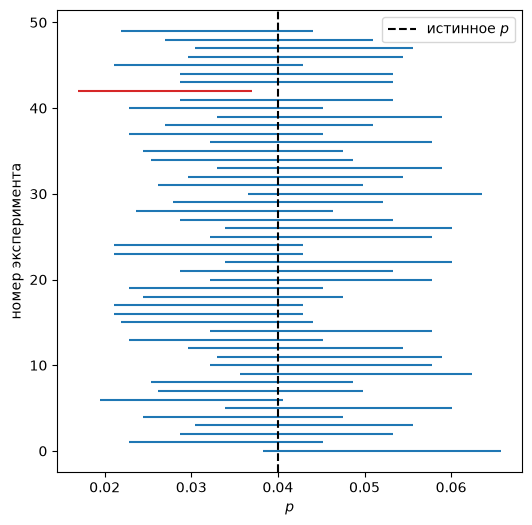

не накрыли: 1 из 50


In [8]:
p, n, K = 0.04, 1000, 50
z = stats.norm.ppf(0.975)

p_hats = rng.binomial(1, p, size=(K, n)).mean(axis=1)
se = np.sqrt(p_hats * (1 - p_hats) / n)
cis = np.column_stack([p_hats - z * se, p_hats + z * se])
covered = (cis[:, 0] <= p) & (p <= cis[:, 1])

plt.figure(figsize=(6, 6))
plt.hlines(np.arange(K), cis[:, 0], cis[:, 1], colors=np.where(covered, "C0", "C3"))
plt.axvline(p, color="black", linestyle="--", label="истинное $p$")
plt.xlabel("$p$")
plt.ylabel("номер эксперимента")
plt.legend()
plt.show()

print(f"не накрыли: {K - covered.sum()} из {K}")